In [1]:
# === BOILERPLATE: locate repo & sessions (if you need them later) ===
import sys
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks, bessel, sosfiltfilt

# --- Optimizations & Progress Bars ---
from tqdm.auto import tqdm
from joblib import Parallel, delayed

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')

# --- CACHE SETUP ---
CACHE_DIR = Path("/home/fsp585/Desktop/FiberphotometryCode/syllable_generation/analysis/replications/datta/processing/1f_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
print(f"Cache directory set to: {CACHE_DIR}")

start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()
for p in (start, *start.parents):
    if p.name == "syllable_generation":
        REPO_ROOT = p
        break
else:
    REPO_ROOT = Path("/home/fsp585/Desktop/FiberphotometryCode/syllable_generation")

PKG_PARENT = REPO_ROOT.parent
for pth in (str(PKG_PARENT), str(REPO_ROOT)):
    if pth not in sys.path:
        sys.path.insert(0, pth)

try:
    import importlib
    importlib.import_module("syllable_generation")
except Exception as e:
    print("Warning: could not import `syllable_generation` (not fatal):", e)

PKL = REPO_ROOT / "loaders" / "jonathan_ifdn_sessions_w_all_data.pkl"
if not PKL.exists():
    loaders_dir = REPO_ROOT / "loaders"
    candidates = list(loaders_dir.glob("*sessions*all_data*.pkl")) + list(loaders_dir.glob("*.pkl"))
    if not candidates:
        raise FileNotFoundError(f"Could not find a sessions pickle under {loaders_dir}")
    PKL = max(candidates, key=lambda p: p.stat().st_mtime)
    print(f"Using fallback pickle: {PKL}")

print(f"Loading sessions from {PKL}...")
with PKL.open("rb") as f:
    sessions = pickle.load(f)

# Quick filter
sessions = [
    s for s in sessions
    if hasattr(s, "all_data_df") and isinstance(s.all_data_df, pd.DataFrame) and not s.all_data_df.empty
]
print(f"Usable sessions with all_data_df: {len(sessions)}")

Cache directory set to: /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/analysis/replications/datta/processing/1f_cache
Using fallback pickle: /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/asdasdasd copy.pkl
Loading sessions from /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/asdasdasd copy.pkl...
Usable sessions with all_data_df: 19


In [2]:
import pandas as pd
from pathlib import Path
import re

# --- 1. Load the Map from the CORRECT path ---
csv_path = Path("/home/fsp585/Desktop/FiberphotometryCode/syllable_generation/projects/jonathan_openfield_example/overrides/animals.csv")

if not csv_path.exists():
    raise FileNotFoundError(f"Cannot find animals.csv at {csv_path}")

print(f"Loading metadata from: {csv_path}")
animal_df = pd.read_csv(csv_path, dtype=str).fillna("")

# Convert to dictionary for fast lookup
animal_map = {}
for _, row in animal_df.iterrows():
    aid = str(row.get("ID", "")).strip()
    if aid:
        animal_map[aid] = {
            "Geno": str(row.get("Geno", "")).strip().upper(),
            "L": str(row.get("Left Hemisphere", "")).strip(),
            "R": str(row.get("Right Hemisphere", "")).strip(),
        }

# --- 2. Patch the Sessions in Memory ---
print(f"Patching {len(sessions)} sessions...")
patched_count = 0

def clean_region_name(raw_name):
    """Converts 'L-DLS' -> 'DLS', 'R-VS' -> 'VS'"""
    if not raw_name: return ""
    # Remove L- or R- prefix (case insensitive) followed by any separator
    s = re.sub(r"^[LRlr][\s\-_]+", "", raw_name)
    return s.strip().upper()

for s in sessions:
    md = s.metadata
    aid = str(md.get("animal_id") or "").strip()
    
    if aid not in animal_map:
        continue
        
    info = animal_map[aid]
    patched_count += 1
    
    # A. Fix Genotype
    if info["Geno"]:
        md["genotype"] = info["Geno"]
        
    # B. Fix Signal Metadata
    smeta = md.get("signal_meta", {})
    
    # Helper to update a specific signal key
    def update_sig(k, raw_region_name):
        if k in smeta and raw_region_name:
            # --- CHANGE: Clean the name before assigning ---
            clean_name = clean_region_name(raw_region_name)
            smeta[k]["brain_reg"] = clean_name
            
            # Enforce hemisphere based on standard wiring
            expected_hemi = "L" if k in ["signal_0", "signal_1"] else "R"
            smeta[k]["hemisphere"] = expected_hemi
            
            # Safety: Ensure Color is set (if loader missed it)
            if "orig_letter" not in smeta[k]:
                idx = int(smeta[k].get("fiber_num", 99))
                smeta[k]["orig_letter"] = "G" if idx % 2 == 0 else "R"

    update_sig("signal_0", info["L"])
    update_sig("signal_1", info["L"])
    update_sig("signal_2", info["R"])
    update_sig("signal_3", info["R"])
    
    # Save back to session
    md["signal_meta"] = smeta

print(f"✅ Successfully patched {patched_count} sessions.")

# --- 3. Verification ---
print("\n--- Verification (Session 0) ---")
print(f"ID: {sessions[0].metadata.get('animal_id')}")
print(f"Genotype: {sessions[0].metadata.get('genotype')}")
print("Signals:")
for k, v in sessions[0].metadata.get("signal_meta", {}).items():
    # Should now show 'DLS' instead of 'L-DLS'
    print(f"  {k}: Reg='{v.get('brain_reg')}' | Hemi='{v.get('hemisphere')}'")

Loading metadata from: /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/projects/jonathan_openfield_example/overrides/animals.csv
Patching 19 sessions...
✅ Successfully patched 19 sessions.

--- Verification (Session 0) ---
ID: 740
Genotype: WT
Signals:
  signal_0: Reg='DMS' | Hemi='L'
  signal_1: Reg='DMS' | Hemi='L'
  signal_2: Reg='VS' | Hemi='R'
  signal_3: Reg='VS' | Hemi='R'


In [3]:
sessions[0].metadata['signal_meta']

{'signal_0': {'orig_fiber': 'G4',
  'orig_letter': 'G',
  'fiber_num': '4',
  'hemisphere': 'L',
  'brain_reg': 'DMS'},
 'signal_1': {'orig_fiber': 'R5',
  'orig_letter': 'R',
  'fiber_num': '5',
  'hemisphere': 'L',
  'brain_reg': 'DMS'},
 'signal_2': {'orig_fiber': 'G6',
  'orig_letter': 'G',
  'fiber_num': '6',
  'hemisphere': 'R',
  'brain_reg': 'VS'},
 'signal_3': {'orig_fiber': 'R7',
  'orig_letter': 'R',
  'fiber_num': '7',
  'hemisphere': 'R',
  'brain_reg': 'VS'}}

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks, bessel, sosfiltfilt


FS = 80.0  # Hz

import numpy as np
import pandas as pd

# --- OPTIMIZED SHUFFLE WORKER (Pure Numpy, No Pandas) ---
def _memmap_shuffle_job_optimized(
    npy_path: str,
    shape: tuple,
    row_groups: np.ndarray, # Integer array mapping each row -> group index
    n_groups: int,
    rng_seed: int,
    fs: float,
    native_fs: float,
    max_shift_blocks: int
):
    """
    Optimized worker:
    1. Reads memmap (Zero-Copy).
    2. Shuffles blocks (Vectorized).
    3. Aggregates by group using pre-calculated integer indices (Pure Numpy).
    """
    # 1. Load Data
    matrix = np.load(npy_path, mmap_mode='r') # (n_snips, n_samples)
    n_snips, n_samples = matrix.shape
    
    # 2. Vectorized Block Shuffle
    rng = np.random.default_rng(rng_seed)
    block_size = int(round(fs / native_fs)) 
    if block_size < 1: block_size = 1
    
    n_blocks = n_samples // block_size
    valid_len = n_blocks * block_size
    
    # Copy core to RAM for shuffling
    core = matrix[:, :valid_len] 
    core_blocked = core.reshape(n_snips, n_blocks, block_size)
    
    max_shift_blocks = min(max_shift_blocks, n_blocks)
    shifts = rng.integers(-max_shift_blocks, max_shift_blocks + 1, size=n_snips)
    
    row_idx = np.arange(n_snips)[:, None]
    block_idx = (np.arange(n_blocks)[None, :] + shifts[:, None]) % n_blocks
    
    shuffled_core = core_blocked[row_idx, block_idx, :].reshape(n_snips, valid_len)
    
    # Handle remainder
    if n_samples > valid_len:
        remainder = matrix[:, valid_len:]
        final_data = np.hstack([shuffled_core, remainder])
    else:
        final_data = shuffled_core

    # 3. Fast Aggregation (No Pandas Groupby)
    # Output shape: (n_groups, n_samples)
    aggregated = np.full((n_groups, n_samples), np.nan, dtype=np.float32)
    
    for g in range(n_groups):
        # Boolean mask for rows belonging to this group
        mask = (row_groups == g)
        if np.any(mask):
            # np.nanmean handles the Manual Exclusion gaps automatically
            aggregated[g, :] = np.nanmean(final_data[mask], axis=0)
            
    return aggregated


def add_kinematics(df: pd.DataFrame, fs: float = FS) -> pd.DataFrame:
    """Add 2D speed, acceleration, jerk, and velocity angle."""
    df = df.copy()

    # --- speed ---
    if "velocity_px_s" in df.columns:
        df["velocity_2d_mm"] = df["velocity_px_s"] * 1.0
    else:
        df["centroid_x_mm"] = df["centroid_x"] * 1.0
        df["centroid_y_mm"] = df["centroid_y"] * 1.0
        dx = np.gradient(df["centroid_x_mm"].to_numpy())
        dy = np.gradient(df["centroid_y_mm"].to_numpy())
        df["velocity_2d_mm"] = np.sqrt(dx**2 + dy**2) * fs

    # --- acceleration & jerk ---
    v = df["velocity_2d_mm"].to_numpy()
    dv = np.gradient(v)
    df["acceleration_2d_mm"] = dv * fs

    da = np.gradient(df["acceleration_2d_mm"].to_numpy())
    df["jerk_2d_mm"] = da * fs

    # --- velocity direction ---
    if "heading" in df.columns:
        df["velocity_angle"] = df["heading"]
    else:
        if "centroid_x" in df.columns and "centroid_y" in df.columns:
            dx = np.gradient(df["centroid_x"].to_numpy()) * fs
            dy = np.gradient(df["centroid_y"].to_numpy()) * fs
            df["velocity_angle"] = np.arctan2(dy, dx)

    return df


def detect_syllable_onsets(
    df: pd.DataFrame, 
    fs: float = 80.0, 
    min_duration_s: float = 0.0 # 150ms minimum duration (Paper standard)
) -> np.ndarray:
    """
    Detects onsets, but discards 'glitches' (syllables lasting < min_duration_s).
    """
    syl = df["syllable"].to_numpy()
    
    # 1. Find changes (0 at start, 1 where value changes)
    # This identifies the frame indices where a NEW syllable starts
    is_change = np.concatenate(([1], syl[1:] != syl[:-1]))
    change_indices = np.flatnonzero(is_change)
    
    # 2. Calculate durations of each bout (in frames)
    # Diff between change indices gives the length of the segment
    run_lengths = np.diff(np.concatenate((change_indices, [len(syl)])))
    
    # 3. Filter: We only want onsets where the *new* bout is long enough
    min_frames = int(min_duration_s * fs)
    valid_mask = (run_lengths >= min_frames)
    
    # Map back to original indices
    valid_onsets = change_indices[valid_mask]
    
    # 4. Remove NaNs (if the syllable itself is NaN, it's not a behavior)
    if len(valid_onsets) > 0:
        valid_values = syl[valid_onsets]
        # Assuming NaNs might be floating point np.nan or None
        # We cast to float to safely check np.isnan
        try:
             is_nan = np.isnan(valid_values.astype(float))
             valid_onsets = valid_onsets[~is_nan]
        except Exception:
            pass # If casting fails, assume valid (e.g. strings/ints)
            
    return valid_onsets


def detect_movement_onsets(
    df: pd.DataFrame,
    fs: float = 80.0
) -> np.ndarray:
    """
    Detect movement initiations at native sampling rate.
    
    Logic mirrors Markowitz et al.:
      1. Z-score velocity (global).
      2. Smooth with 1.67s boxcar (matches 50 frames @ 30Hz).
      3. Compute derivative (d(std)/dt) and cube it.
      4. Find peaks > 1.0.
    """
    # Ensure we have valid data
    v = df["velocity_2d_mm"].to_numpy()
    if len(v) == 0:
        return np.array([], dtype=int)

    # --- 1. Global Z-score ---
    # The paper z-scores velocity across the whole session 
    v_mean = np.nanmean(v)
    v_std = np.nanstd(v)
    
    if v_std == 0 or np.isnan(v_std):
        return np.array([], dtype=int)
        
    v_z = (v - v_mean) / v_std

    # --- 2. Smoothing (1.67 seconds) ---
    # Paper used 50 frames at 30Hz = 1.667 seconds 
    # We calculate equivalent frames for current fs
    win_sec = 1.667
    win_frames = int(round(win_sec * fs))
    
    v_smooth = uniform_filter1d(v_z, size=win_frames, mode="nearest")

    # --- 3. Derivative & Cube ---
    # CRITICAL: Multiply by fs to convert "diff per frame" to "diff per second"
    # This matches the physical units of the threshold (1 std/sec)
    dv = np.diff(v_smooth, prepend=v_smooth[0]) * fs
    cp_score = dv ** 3

    # --- 4. Peak Detection ---
    # Thresholds from paper: height=1, width=1, prominence=1 [cite: 1164]
    # We keep width=1 (1 sample) to be permissive of sharp onsets
    peaks, _ = find_peaks(cp_score, height=1, width=1, prominence=1)

    return peaks

def choose_dlight_column(df: pd.DataFrame, sig_key: str) -> str:
    candidates = [
        f"{sig_key}_zscore_datta",
        f"{sig_key}_zscore",
        f"{sig_key}_dff_z",
        f"{sig_key}_dff",
        sig_key,
    ]
    for c in candidates:
        if c in df.columns:
            return c
    raise KeyError(f"No dLight column found for {sig_key} in df.columns")


def extract_snippets_for_session(
    session,
    area: str,
    target_hemi: str = None,   
    target_color: str = None,  
    fs: float = 80.0,
    pre_s: float = -10.0,
    post_s: float = 10.0,
) -> pd.DataFrame:
    
    df = session.all_data_df.copy()
    df = df.reset_index(drop=True)
    
    # ... [Keep Metadata Matching Logic Same as Before] ...
    meta = session.metadata
    signal_meta = meta.get("signal_meta", {}) or {}
    sig_key = None
    
    for key, info in signal_meta.items():
        # ... (Your existing matching logic) ...
        reg_match  = str(info.get("brain_reg", "")).lower() == area.lower()
        hemi_val = str(info.get("hemisphere", "")).upper()
        hemi_match = (hemi_val == target_hemi) if target_hemi else True
        color_val = str(info.get("orig_letter", "")).upper()
        if not color_val and "fiber_num" in info:
            fnum = int(info["fiber_num"])
            color_val = "G" if fnum % 2 == 0 else "R"
        color_match = (color_val == target_color) if target_color else True
        
        if reg_match and hemi_match and color_match:
            sig_key = key
            break

    if sig_key is None:
        return pd.DataFrame() 

    # --- OPTIMIZATION START ---
    # Instead of calculating kinematics here, assume they exist
    df = session.all_data_df
    
    # Check if pre-calc happened (sanity check)
    if "velocity_2d_mm" not in df.columns:
        # Fallback if you forgot to run pre-process
        df = add_kinematics(df, fs=fs) 
    
    # Use Cached Onsets
    if hasattr(session, "cached_syllable_onsets"):
        syll_onsets = session.cached_syllable_onsets
        movement_onsets = session.cached_movement_onsets
    else:
        # Fallback
        syll_onsets = detect_syllable_onsets(df, fs=fs)
        movement_onsets = detect_movement_onsets(df, fs=fs)
    # --- OPTIMIZATION END ---

    try:
        dlight_col = choose_dlight_column(df, sig_key)
    except KeyError:
        return pd.DataFrame()

    n_frames = len(df)
    pre_f = int(round(pre_s * fs))
    post_f = int(round(post_s * fs))
    window_len = post_f - pre_f + 1
    
    # Get arrays (Kinematics already in DF)
    dlight = df[dlight_col].to_numpy()
    v = df["velocity_2d_mm"].to_numpy()
    a = df["acceleration_2d_mm"].to_numpy()
    j = df["jerk_2d_mm"].to_numpy()
    ang = df["velocity_angle"].to_numpy() if "velocity_angle" in df.columns else np.zeros(n_frames)
    
    # ... [Keep helper function get_snippets same as before] ...
    
    def get_snippets(indices, label):
        # ... (Keep existing implementation) ...
        valid_mask = (indices + pre_f >= 0) & (indices + post_f < n_frames)
        valid_centers = indices[valid_mask]
        
        if len(valid_centers) == 0:
            return None

        n_events = len(valid_centers)
        window_offsets = np.arange(pre_f, post_f + 1)
        indexer = valid_centers[:, None] + window_offsets[None, :] 
        
        d_flat = dlight[indexer].ravel()
        v_flat = v[indexer].ravel()
        a_flat = a[indexer].ravel()
        j_flat = j[indexer].ravel()
        ang_flat = ang[indexer].ravel()
        x_s_flat = np.tile(window_offsets, n_events)
        
        s_id_base = f"{session.session_id}_{area}_{target_hemi}_{target_color}_{label}"
        snippet_ids = [f"{s_id_base}_{i}" for i in range(n_events)]
        snip_flat = np.repeat(snippet_ids, window_len)
        
        return pd.DataFrame({
            "uuid": session.session_id,
            "mouse_id": meta.get("animal_id", meta.get("mouse_id", "UNK")),
            "genotype": meta.get("genotype", "UNK"),
            "area": area,
            "hemisphere": target_hemi, 
            "color": target_color,     
            "init_type": label,
            "snippet": snip_flat,
            "x_samples": x_s_flat,
            "x": x_s_flat / fs,
            "dff_z": d_flat,
            "velocity_2d_mm": v_flat,
            "acceleration_2d_mm": a_flat,
            "jerk_2d_mm": j_flat,
            "velocity_angle": ang_flat,
        })

    dfs = []
    if len(syll_onsets) > 0: dfs.append(get_snippets(syll_onsets, "syllable"))
    if len(movement_onsets) > 0: dfs.append(get_snippets(movement_onsets, "movement"))
        
    dfs = [d for d in dfs if d is not None]
    if not dfs: return pd.DataFrame()

    return pd.concat(dfs, ignore_index=True)


def prepare_snippets_markowitz_optimized(
    snippet_df: pd.DataFrame, 
    fs: float = 80.0,
    norm_window: tuple[float, float] = (-10.0, 10.0)
) -> pd.DataFrame:
    """
    Vectorized version of normalization.
    Avoids .groupby().transform() which is slow for thousands of snippets.
    """
    df = snippet_df.copy()
    
    # 1. Pivot to Matrix (Snippets x Time)
    # This aligns everything perfectly
    # We rely on 'snippet' and 'x_samples' being unique keys
    matrix_df = df.pivot(index="snippet", columns="x_samples", values="dff_z")
    
    # 2. Identify Norm Columns (Time window)
    # x_samples are integers. Convert norm_window (seconds) to samples relative to 0
    # Note: We need to know the 'x' values mapping. 
    # Faster approach: Filter the long DF once to find valid x_samples
    norm_mask = df["x"].between(norm_window[0], norm_window[1])
    valid_samples = df.loc[norm_mask, "x_samples"].unique()
    
    # 3. Calculate Stats (Vectorized on Matrix)
    # Select columns that fall in the window
    norm_cols = [c for c in matrix_df.columns if c in valid_samples]
    
    if not norm_cols:
        # Fallback if window is missing (shouldn't happen)
        mu = matrix_df.mean(axis=1)
        sig = matrix_df.std(axis=1)
    else:
        mu = matrix_df[norm_cols].mean(axis=1)
        sig = matrix_df[norm_cols].std(axis=1)
    
    sig[sig == 0] = 1.0
    
    # 4. Apply Z-Score (Broadcasting)
    # (Matrix - Vec) / Vec
    z_matrix = (matrix_df.sub(mu, axis=0)).div(sig, axis=0)
    
    # 5. Vectorized High-Pass Filter
    # Apply to the whole matrix at once (axis=1 is time)
    sos = bessel(1, 1.0 / (fs / 2.0), btype="high", output="sos")
    
    # Handle NaNs: fill with 0 for filter, then put back? 
    # Or just let filter propagate NaNs (standard behavior, safer)
    filtered_vals = sosfiltfilt(sos, z_matrix.values, axis=1)
    
    # 6. Melt back to Long Format
    # We reconstruct the dataframe to match the original structure
    z_matrix_hp = pd.DataFrame(filtered_vals, index=z_matrix.index, columns=z_matrix.columns)
    
    long_hp = z_matrix_hp.reset_index().melt(id_vars="snippet", var_name="x_samples", value_name="dff_hp")
    
    # 7. Merge back to original (Preserves metadata columns)
    # We join on [snippet, x_samples]
    df = pd.merge(df, long_hp, on=["snippet", "x_samples"], how="left")
    
    return df

import tempfile
import os

def compute_shuffle_z_optimized(
    snippet_df: pd.DataFrame,
    fs: float = 80.0,
    time_window: tuple[float, float] = (-1.5, 1.5),
    n_shuffles: int = 200,
    random_state: int | None = None,
):
    rng = np.random.default_rng(random_state)

    # 1. Filter Time Window
    min_samp = int(round(time_window[0] * fs))
    max_samp = int(round(time_window[1] * fs))
    
    # Sort carefully for matrix reshaping
    df_plot = snippet_df[
        snippet_df["x_samples"].between(min_samp, max_samp)
    ].sort_values(["snippet", "x_samples"])

    if df_plot.empty: raise ValueError("No data in window")

    # 2. Prepare Matrix (Float32 for speed)
    snippet_ids, counts = np.unique(df_plot["snippet"].to_numpy(), return_counts=True)
    n_snips = len(snippet_ids)
    n_samples = counts[0]
    
    if not np.all(counts == n_samples):
        # Fallback: Pivot if ragged (slower but safe)
        pivot = df_plot.pivot(index="snippet", columns="x_samples", values="dff_hp")
        raw_signal = pivot.values.astype("float32")
        snippet_ids = pivot.index.values
        n_snips, n_samples = raw_signal.shape
        # Re-extract metadata based on pivot index
        # We take the first entry of each snippet for metadata
        meta_df = df_plot.drop_duplicates("snippet").set_index("snippet").loc[snippet_ids]
    else:
        raw_signal = df_plot["dff_hp"].to_numpy(dtype="float32").reshape(n_snips, n_samples)
        meta_df = df_plot.iloc[::n_samples].copy() # Take 1st row of each snippet

    # 3. Prepare Groups for Vectorized Aggregation
    # We map ("init_type", "mouse_id") -> Integer ID
    group_keys = ["init_type", "mouse_id"]
    
    # Create unique group identifiers
    # ngroup() is fast
    grouped_meta = meta_df.groupby(group_keys, observed=True)
    row_groups = grouped_meta.ngroup().to_numpy().astype(np.int32)
    n_groups = row_groups.max() + 1
    
    # Save mapping for reconstruction later
    # group_id -> (init_type, mouse_id)
    group_map = grouped_meta.first().index.to_frame(index=False).reset_index(drop=True)

    # Calculate Observed Mean (Fast)
    # We reuse the optimized worker logic with seed=None or just numpy
    # But simple groupby mean on the meta_df + raw signal is easy enough:
    # Actually, simpler: use the same row_groups logic
    observed_agg = np.zeros((n_groups, n_samples), dtype=np.float32)
    for g in range(n_groups):
        mask = (row_groups == g)
        if np.any(mask):
            observed_agg[g, :] = np.nanmean(raw_signal[mask], axis=0)

    # 4. Memmap Setup
    npy_path = CACHE_DIR / "temp_memmap_fast.npy"
    if npy_path.exists(): npy_path.unlink()
    
    try:
        np.save(npy_path, raw_signal)
        
        # 5. Run Parallel Shuffles
        print(f"   Dispatching {n_shuffles} optimized jobs...")
        seeds = rng.integers(0, 1e9, size=n_shuffles)
        
        # Returns list of (n_groups, n_samples) arrays
        results_list = Parallel(n_jobs=-1, backend="loky")(
            delayed(_memmap_shuffle_job_optimized)(
                npy_path=npy_path,
                shape=(n_snips, n_samples),
                row_groups=row_groups,
                n_groups=n_groups,
                rng_seed=seed,
                fs=fs,
                native_fs=20.0,
                max_shift_blocks=60
            )
            for seed in tqdm(seeds, desc="Shuffling", leave=False)
        )
        
    finally:
        if npy_path.exists(): npy_path.unlink()

    # 6. Reconstruct DataFrame
    # Stack results: (n_shuffles, n_groups, n_samples)
    stack = np.array(results_list) # shape: (N_shuff, N_groups, N_time)
    
    # Calculate Shuffle Stats (Vectorized across shuffles)
    # Axis 0 is shuffles
    shuffle_mu_arr = np.nanmean(stack, axis=0) # (N_groups, N_time)
    shuffle_sig_arr = np.nanstd(stack, axis=0, ddof=1)
    
    # Z-Score Observed
    obs_z_arr = (observed_agg - shuffle_mu_arr) / shuffle_sig_arr
    
    # 7. Format Output (Re-attach metadata)
    # We need to map back from (Group ID, Time Index) -> DataFrame
    
    # Get Time Index from original df
    time_cols = np.sort(df_plot["x_samples"].unique())
    
    # Construct "pop_stats" style DF
    # We need to average across mice for the final plot (init_type, time)
    # Currently `obs_z_arr` is per (init_type, mouse).
    
    # Let's create a DataFrame for the Z-scores
    # Index: [init_type, mouse_id], Columns: [time_indices]
    z_df_wide = pd.DataFrame(
        obs_z_arr, 
        index=pd.MultiIndex.from_frame(group_map),
        columns=time_cols
    )
    
    # Melt to long: [init_type, mouse_id, x_samples, z]
    z_df_long = z_df_wide.stack().rename("z").reset_index()
    z_df_long = z_df_long.rename(columns={"level_2": "x_samples"}) # if stack names it level_X
    
    # Now aggregate across mice (Grand Mean)
    stats = (
        z_df_long.groupby(["init_type", "x_samples"])["z"]
        .agg(["mean", "std", "count"])
        .rename(columns={"mean": "z_mean", "std": "z_std"})
    )
    sem = stats["z_std"] / np.sqrt(stats["count"].clip(lower=1))
    stats["z_lo"] = stats["z_mean"] - 1.96 * sem
    stats["z_hi"] = stats["z_mean"] + 1.96 * sem
    pop_stats = stats[["z_mean", "z_lo", "z_hi"]]
    
    # 8. Grey Bands (Global Percentiles)
    # We pool all shuffle Z-values
    # Z_shuffle = (Shuffle_val - Shuffle_mean) / Shuffle_std
    # Note: Shuffle_val is `stack`. Shuffle_mean is `shuffle_mu_arr`.
    
    # Broadcasting subtraction/division
    # stack: (Shuff, Group, Time)
    # mu: (1, Group, Time)
    z_null_stack = (stack - shuffle_mu_arr[None, :, :]) / shuffle_sig_arr[None, :, :]
    
    # Flatten valid values
    z_null_flat = z_null_stack.ravel()
    z_null_flat = z_null_flat[np.isfinite(z_null_flat)]
    
    if z_null_flat.size:
        grey_lo, grey_hi = np.percentile(z_null_flat, [2.5, 97.5])
    else:
        grey_lo, grey_hi = -1, 1
        
    # 9. Derivative Band (Optional, kept simple)
    # Calculating deriv on the stack (Shuff, Group, Time) along axis 2
    grad_stack = np.gradient(z_null_stack, 1.0/fs, axis=2)
    grad_flat = grad_stack.ravel()
    grad_flat = grad_flat[np.isfinite(grad_flat)]
    
    if grad_flat.size:
        grey_d_lo, grey_d_hi = np.percentile(grad_flat, [2.5, 97.5])
    else:
        grey_d_lo, grey_d_hi = -1, 1

    # Return same signature as before
    # Note: `observed_z` (raw series) is harder to reconstruct perfectly but we return the long DF
    # The original returned a Series indexed by (init_type, mouse_id, x_samples)
    return pop_stats, (grey_lo, grey_hi), (grey_d_lo, grey_d_hi), z_df_long.set_index(["init_type", "mouse_id", "x_samples"])["z"]

def plot_fig1f_style(
    pop_stats: pd.DataFrame,
    grey_band: tuple[float, float],
    grey_band_deriv: tuple[float, float],
    fs: float = FS,
    title: str | None = None,
):
    """Standard plotting function."""
    pop_stats = pop_stats.copy().sort_index()

    fig, (ax_top, ax_bot) = plt.subplots(
        2, 1, figsize=(4, 4), sharex=True, gridspec_kw={"height_ratios": [2.0, 1.0]}
    )

    colors = {"syllable": "tab:green", "movement": "tab:orange"}
    time_window = (-1.5, 1.5)

    # --- Top panel ---
    for init_type in pop_stats.index.get_level_values("init_type").unique():
        stats_type = pop_stats.xs(init_type, level="init_type")
        t = stats_type.index.to_numpy() / fs
        m = stats_type["z_mean"].to_numpy()
        lo = stats_type["z_lo"].to_numpy()
        hi = stats_type["z_hi"].to_numpy()

        color = colors.get(init_type, "k")
        ax_top.plot(t, m, color=color, lw=1.5, label=init_type)
        ax_top.fill_between(t, lo, hi, color=color, alpha=0.3, linewidth=0)

    ax_top.axvline(0.0, ls="--", color="k", alpha=0.8, zorder=10)

    g_lo, g_hi = grey_band
    ax_top.axhspan(g_lo, g_hi, color="0.85", zorder=-10)
    ax_top.set_ylabel("ΔF/F₀ (z to shuffle)")
    ax_top.legend(frameon=False)
    ax_top.set_xlim(time_window)

    # --- Bottom panel ---
    if "syllable" in pop_stats.index.get_level_values("init_type"):
        syl_stats = pop_stats.xs("syllable", level="init_type")
        t = syl_stats.index.to_numpy() / fs
        z = syl_stats["z_mean"].to_numpy()
        lo = syl_stats["z_lo"].to_numpy()
        hi = syl_stats["z_hi"].to_numpy()

        dz = np.gradient(z, 1.0 / fs)
        dz_lo = np.gradient(lo, 1.0 / fs)
        dz_hi = np.gradient(hi, 1.0 / fs)

        ax_bot.plot(t, dz, color="tab:green", lw=1.5)
        ax_bot.fill_between(t, dz_lo, dz_hi, color="tab:green", alpha=0.3, linewidth=0)

    ax_bot.axvline(0.0, ls="--", color="k", alpha=0.8, zorder=10)
    d_lo, d_hi = grey_band_deriv
    ax_bot.axhspan(d_lo, d_hi, color="0.85", zorder=-10)

    ax_bot.set_ylabel("d(ΔF/F₀)/dt\n(z to shuffle)")
    ax_bot.set_xlabel("Time from onset (s)")
    ax_bot.set_xlim(time_window)

    if title is not None:
        fig.suptitle(title)

    fig.tight_layout()
    return fig


import gc  # Garbage Collector interface

def process_and_plot_single_combo(
    sessions: list,
    genotype: str,
    area: str,
    hemi: str,   # <--- Input arg
    color: str,  # <--- Input arg
    fs: float = 80.0,
    pre_s: float = -10.0,
    post_s: float = 10.0,
    n_shuffles: int = 200,
    random_state: int = 0,
    cache_dir: Path = CACHE_DIR,
):
    # Unique ID for this specific combination
    combo_name = f"{genotype} {area} ({hemi}-{color})"
    print(f"\n=== Processing: {combo_name} ===")
    
    # --- 1. Check Level 2 Cache (UPDATED FILENAME) ---
    # This ensures "Left Green" gets its own file, distinct from "Right Red"
    stats_cache_file = cache_dir / f"stats_{genotype}_{area}_{hemi}_{color}_opt.pkl"
    
    if stats_cache_file.exists():
        print(f"   [CACHE HIT] Loading: {stats_cache_file.name}")
        try:
            with open(stats_cache_file, "rb") as f:
                pop_stats, grey_band, grey_band_deriv, observed_z = pickle.load(f)
            
            # Generate the plot from the loaded stats
            fig = plot_fig1f_style(pop_stats, grey_band, grey_band_deriv, fs=fs, title=combo_name)
            return fig, pop_stats, observed_z
        except Exception as e:
            print(f"   [CACHE ERROR] Corrupted ({e}), recomputing...")

    # --- 2. Filter Sessions ---
    target_sessions = [
        s for s in sessions 
        if (getattr(s, "metadata", {}) or {}).get("genotype", "UNK") == genotype
    ]
    if not target_sessions: return None, None, None

    # --- 3. Extract Snippets ---
    combo_snippets = []
    n_kept = 0
    
    for sess in tqdm(target_sessions, desc="Extracting", leave=False):
        # Pass hemi/color to the extractor
        snip = extract_snippets_for_session(
            sess, area=area, target_hemi=hemi, target_color=color,
            fs=fs, pre_s=pre_s, post_s=post_s
        )
        if not snip.empty:
            combo_snippets.append(snip)
            n_kept += 1

    if not combo_snippets:
        print(f"   No data found for {combo_name}.")
        return None, None, None

    # Combine & Clean
    df_combo = pd.concat(combo_snippets, ignore_index=True)
    del combo_snippets; gc.collect()

    # --- 4. Prepare ---
    print(f"   Normalizing {len(df_combo)} rows...")
    df_combo = prepare_snippets_markowitz_optimized(df_combo, fs=fs, norm_window=(-10.0, 10.0))
    
    analysis_window = (-1.5, 1.5)
    df_combo = df_combo[df_combo["x"].between(*analysis_window)].copy()

    # --- 5. Compute Stats ---
    print("   Running Shuffle...")
    pop_stats, grey_band, grey_band_deriv, observed_z = compute_shuffle_z_optimized(
        df_combo, fs=fs, time_window=analysis_window,
        n_shuffles=n_shuffles, random_state=random_state,
    )

    # --- 6. Save & Plot ---
    print(f"   Saving stats to {stats_cache_file.name}...")
    with open(stats_cache_file, "wb") as f:
        pickle.dump((pop_stats, grey_band, grey_band_deriv, observed_z), f)

    fig = plot_fig1f_style(pop_stats, grey_band, grey_band_deriv, fs=fs, title=f"{combo_name} (n={n_kept})")
    
    del df_combo; gc.collect()
    return fig, pop_stats, observed_z

In [5]:
def preprocess_sessions_kinematics(sessions, fs=80.0):
    """
    Optimizes the pipeline by calculating Kinematics and Onsets ONCE per session,
    rather than re-calculating them for every brain region loop.
    """
    print(f"--- Pre-calculating Kinematics & Onsets for {len(sessions)} sessions ---")
    
    for s in tqdm(sessions, desc="Pre-processing"):
        # 1. Calculate Kinematics (Speed, Accel, Jerk) inplace
        # This adds columns: velocity_2d_mm, acceleration_2d_mm, jerk_2d_mm
        s.all_data_df = add_kinematics(s.all_data_df, fs=fs)
        
        # 2. Detect Onsets (Global to the animal)
        # We attach these as new attributes to the session object so they travel with it
        s.cached_syllable_onsets = detect_syllable_onsets(s.all_data_df, fs=fs)
        s.cached_movement_onsets = detect_movement_onsets(s.all_data_df, fs=fs)
        
    print("Done. Kinematics added to .all_data_df and onsets cached to session objects.")

# === RUN THIS IMMEDIATELY AFTER LOADING SESSIONS ===
preprocess_sessions_kinematics(sessions, fs=80.0)

--- Pre-calculating Kinematics & Onsets for 19 sessions ---


Pre-processing:   0%|          | 0/19 [00:00<?, ?it/s]

Done. Kinematics added to .all_data_df and onsets cached to session objects.



=== Processing: WT DLS (L-G) ===


Extracting:   0%|          | 0/7 [00:00<?, ?it/s]

   Normalizing 25300603 rows...
   Running Shuffle...
   Dispatching 200 optimized jobs...


Shuffling:   0%|          | 0/200 [00:00<?, ?it/s]

   Saving stats to stats_WT_DLS_L_G_opt.pkl...
Result: WT-DLS L (G)


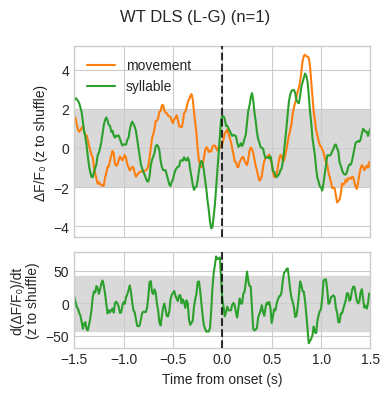


=== Processing: WT DLS (R-G) ===


Extracting:   0%|          | 0/7 [00:00<?, ?it/s]

   Normalizing 73972604 rows...
   Running Shuffle...
   Dispatching 200 optimized jobs...


Shuffling:   0%|          | 0/200 [00:00<?, ?it/s]

   Saving stats to stats_WT_DLS_R_G_opt.pkl...
Result: WT-DLS R (G)


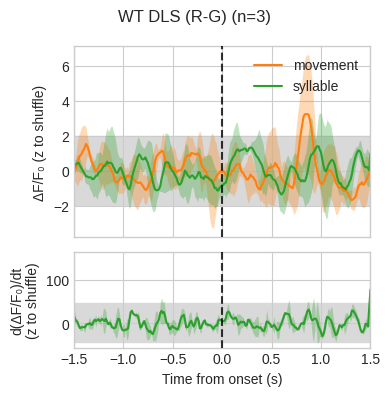


=== Processing: WT DMS (L-G) ===


Extracting:   0%|          | 0/7 [00:00<?, ?it/s]

   Normalizing 50345046 rows...
   Running Shuffle...
   Dispatching 200 optimized jobs...


Shuffling:   0%|          | 0/200 [00:00<?, ?it/s]

   Saving stats to stats_WT_DMS_L_G_opt.pkl...
Result: WT-DMS L (G)


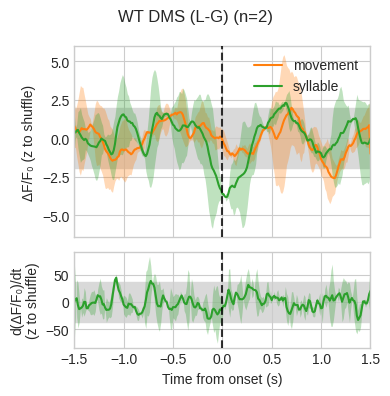


=== Processing: WT DMS (R-G) ===


Extracting:   0%|          | 0/7 [00:00<?, ?it/s]

   Normalizing 26935224 rows...
   Running Shuffle...
   Dispatching 200 optimized jobs...


Shuffling:   0%|          | 0/200 [00:00<?, ?it/s]

   Saving stats to stats_WT_DMS_R_G_opt.pkl...
Result: WT-DMS R (G)


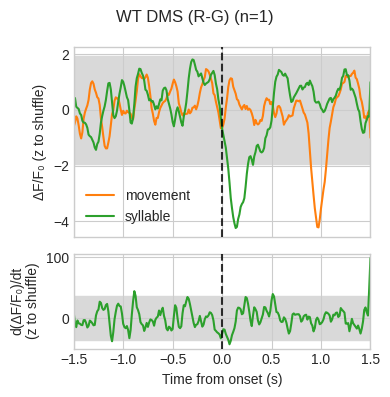


=== Processing: WT VS (L-G) ===


Extracting:   0%|          | 0/7 [00:00<?, ?it/s]

   Normalizing 73900559 rows...
   Running Shuffle...
   Dispatching 200 optimized jobs...


Shuffling:   0%|          | 0/200 [00:00<?, ?it/s]

   Saving stats to stats_WT_VS_L_G_opt.pkl...
Result: WT-VS L (G)


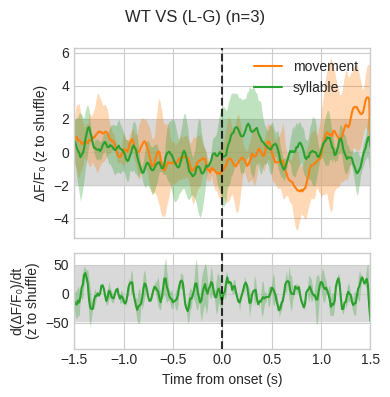


=== Processing: WT VS (R-G) ===


Extracting:   0%|          | 0/7 [00:00<?, ?it/s]

   Normalizing 73710040 rows...
   Running Shuffle...
   Dispatching 200 optimized jobs...


Shuffling:   0%|          | 0/200 [00:00<?, ?it/s]

/tmp/ipykernel_547640/768792937.py:503: RuntimeWarning: invalid value encountered in divide
  obs_z_arr = (observed_agg - shuffle_mu_arr) / shuffle_sig_arr
/tmp/ipykernel_547640/768792937.py:546: RuntimeWarning: invalid value encountered in divide
  z_null_stack = (stack - shuffle_mu_arr[None, :, :]) / shuffle_sig_arr[None, :, :]


   Saving stats to stats_WT_VS_R_G_opt.pkl...
Result: WT-VS R (G)


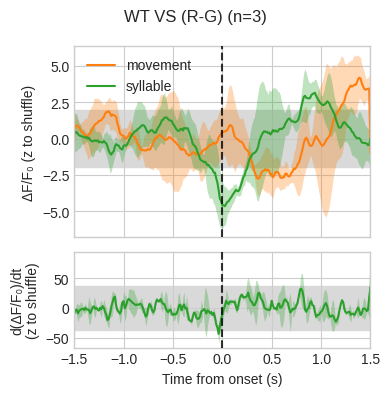


=== Processing: KI DLS (L-G) ===


Extracting:   0%|          | 0/8 [00:00<?, ?it/s]

   Normalizing 48921757 rows...
   Running Shuffle...
   Dispatching 200 optimized jobs...


Shuffling:   0%|          | 0/200 [00:00<?, ?it/s]

   Saving stats to stats_KI_DLS_L_G_opt.pkl...
Result: KI-DLS L (G)


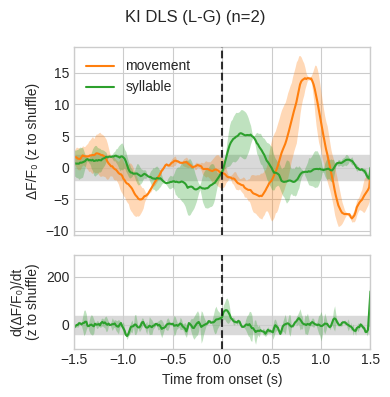


=== Processing: KI DLS (R-G) ===


Extracting:   0%|          | 0/8 [00:00<?, ?it/s]

   Normalizing 48151676 rows...
   Running Shuffle...
   Dispatching 200 optimized jobs...


Shuffling:   0%|          | 0/200 [00:00<?, ?it/s]

   Saving stats to stats_KI_DLS_R_G_opt.pkl...
Result: KI-DLS R (G)


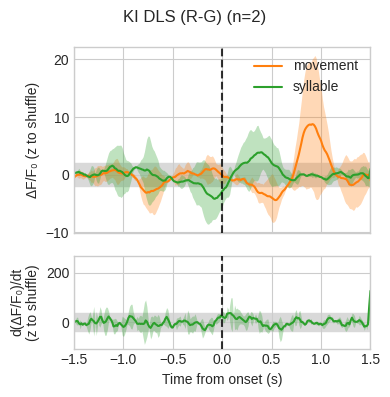


=== Processing: KI DMS (L-G) ===


Extracting:   0%|          | 0/8 [00:00<?, ?it/s]

   Normalizing 71897708 rows...
   Running Shuffle...
   Dispatching 200 optimized jobs...


Shuffling:   0%|          | 0/200 [00:00<?, ?it/s]

   Saving stats to stats_KI_DMS_L_G_opt.pkl...
Result: KI-DMS L (G)


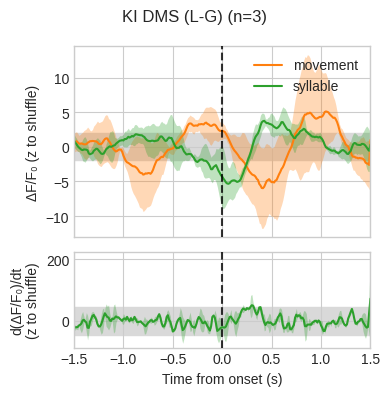


=== Processing: KI DMS (R-G) ===


Extracting:   0%|          | 0/8 [00:00<?, ?it/s]

   Normalizing 50487535 rows...
   Running Shuffle...
   Dispatching 200 optimized jobs...


Shuffling:   0%|          | 0/200 [00:00<?, ?it/s]

   Saving stats to stats_KI_DMS_R_G_opt.pkl...
Result: KI-DMS R (G)


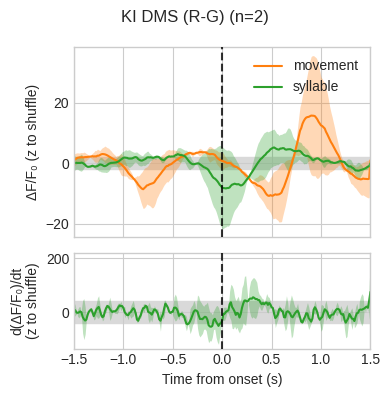


=== Processing: KI VS (L-G) ===


Extracting:   0%|          | 0/8 [00:00<?, ?it/s]

   Normalizing 50487535 rows...
   Running Shuffle...
   Dispatching 200 optimized jobs...


Shuffling:   0%|          | 0/200 [00:00<?, ?it/s]

   Saving stats to stats_KI_VS_L_G_opt.pkl...
Result: KI-VS L (G)


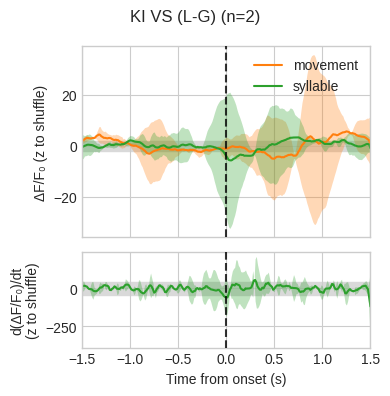


=== Processing: KI VS (R-G) ===


Extracting:   0%|          | 0/8 [00:00<?, ?it/s]

   Normalizing 77798994 rows...
   Running Shuffle...
   Dispatching 200 optimized jobs...


Shuffling:   0%|          | 0/200 [00:00<?, ?it/s]

   Saving stats to stats_KI_VS_R_G_opt.pkl...
Result: KI-VS R (G)


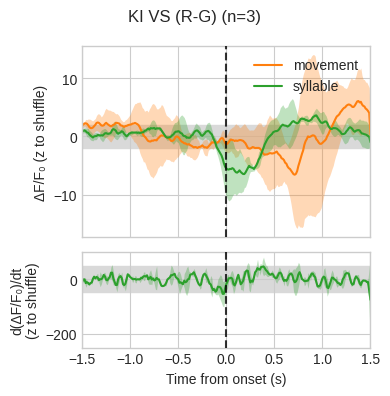


All combinations processed.


In [6]:
# === CONFIG ===
genotypes = ["WT", "KI"]
areas = ["DLS", "DMS", "VS"]
hemispheres = ["L", "R"] # Matches metadata 'hemisphere'
colors = ["G"]      # Matches metadata 'orig_letter' or Fiber 0/1 logic
FS = 80.0

results = {}

for geno in genotypes:
    for area in areas:
        for hemi in hemispheres:
            for color in colors:
                
                # Run processor
                res = process_and_plot_single_combo(
                    sessions,
                    genotype=geno,
                    area=area,
                    hemi=hemi,   # <--- New Param
                    color=color, # <--- New Param
                    fs=FS,
                    pre_s=-10.0,
                    post_s=10.0,
                    n_shuffles=200,
                    random_state=0
                )
                
                if res[0] is not None:
                    fig, stats, z = res
                    # Store with full key
                    results[(geno, area, hemi, color)] = (fig, stats, z)
                    
                    print(f"Result: {geno}-{area} {hemi} ({color})")
                    display(fig)
                    plt.close(fig)
                    
                gc.collect()

print("\nAll combinations processed.")

In [7]:
# ==========================================
# 5. LATERALIZATION PROCESSOR (L - R)
# ==========================================

def calculate_diff_stats(stats_L, stats_R):
    """
    Mathematically derives (L - R) statistics from the cached dataframes.
    Assumes indices (init_type, x_samples) align perfectly.
    """
    # 1. Calculate Mean Difference
    diff_stats = stats_L.copy()
    diff_stats["z_mean"] = stats_L["z_mean"] - stats_R["z_mean"]
    
    # 2. Propagate Error (Square Root of Sum of Squares)
    # Margin = Hi - Mean
    margin_L = stats_L["z_hi"] - stats_L["z_mean"]
    margin_R = stats_R["z_hi"] - stats_R["z_mean"]
    
    # New Margin = sqrt(L_err^2 + R_err^2)
    margin_diff = np.sqrt(margin_L**2 + margin_R**2)
    
    diff_stats["z_hi"] = diff_stats["z_mean"] + margin_diff
    diff_stats["z_lo"] = diff_stats["z_mean"] - margin_diff
    
    return diff_stats

def calculate_diff_band(band_L, band_R):
    """
    Estimates the new Null Distribution (Grey Band) width.
    Assumes Null distributions are roughly centered on 0 and independent.
    """
    # Band width (half-width)
    w_L = (band_L[1] - band_L[0]) / 2
    w_R = (band_R[1] - band_R[0]) / 2
    
    # Combined width
    w_diff = np.sqrt(w_L**2 + w_R**2)
    
    return (-w_diff, w_diff)

def process_lateralization(genotype, area, color, fs=80.0, cache_dir=CACHE_DIR):
    """Loads L and R caches, computes difference, and plots."""
    
    # Construct filenames
    file_L = cache_dir / f"stats_{genotype}_{area}_L_{color}_opt.pkl"
    file_R = cache_dir / f"stats_{genotype}_{area}_R_{color}_opt.pkl"
    
    if not file_L.exists() or not file_R.exists():
        # This happens if one side had no data
        return None

    # Load Caches
    stats_L, band_L, deriv_L, _ = pickle.load(open(file_L, 'rb'))
    stats_R, band_R, deriv_R, _ = pickle.load(open(file_R, 'rb'))
    
    # --- MATH: L minus R ---
    pop_stats_diff = calculate_diff_stats(stats_L, stats_R)
    band_diff = calculate_diff_band(band_L, band_R)
    deriv_diff = calculate_diff_band(deriv_L, deriv_R)
    
    # --- PLOT ---
    title = f"{genotype} {area} (L-R) | {color}"
    fig = plot_fig1f_style(pop_stats_diff, band_diff, deriv_diff, fs=fs, title=title)
    
    return fig

# --- CONFIG FOR LATERALIZATION ---
LATERAL_GENOTYPES = ["WT", "KI"]
LATERAL_AREAS = ["DLS", "DMS", "VS"]
LATERAL_COLORS = ["G"] # Plot difference for Signal (G) and Artifact (R)

print("\n=== Generating L-R Lateralization Plots ===")

for geno in LATERAL_GENOTYPES:
    for area in LATERAL_AREAS:
        for color in LATERAL_COLORS:
            
            fig = process_lateralization(geno, area, color, fs=FS)
            
            if fig is not None:
                # Save with distinct name
                save_path = CACHE_DIR / f"plot_{geno}_{area}_L-R_{color}.png"
                fig.savefig(save_path, dpi=100, bbox_inches='tight')
                
                print(f"Generated: {save_path.name}")
                # display(fig) # Uncomment to see inline
                plt.close(fig)
            else:
                pass # print(f"Skipping {geno}-{area} (Missing L or R data)")

print("Lateralization processing complete.")


=== Generating L-R Lateralization Plots ===
Generated: plot_WT_DLS_L-R_G.png
Generated: plot_WT_DMS_L-R_G.png
Generated: plot_WT_VS_L-R_G.png
Generated: plot_KI_DLS_L-R_G.png
Generated: plot_KI_DMS_L-R_G.png
Generated: plot_KI_VS_L-R_G.png
Lateralization processing complete.
